# Demo 0 — Toán nền và Grover
**Người nói 1 · 11:00–12:30 (1 phút 30)**

Cell 2 hiện output đã lưu; cell 3–4 chạy trực tiếp.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qsvt_demo import *
import qsvt_demo

plt.rcParams.update({"font.size": 13, "figure.figsize": (8, 3.6), "axes.grid": True})
reset_rng()
print(f"Qiskit {qiskit.__version__} | numpy {np.__version__} | seed {SEED}")

Qiskit 2.6.2 | numpy 2.5.5 | seed 1234


## Cell 2 — E0 rút gọn: Helstrom, Werner, hậu chọn
Helstrom: phân biệt |0⟩ và |+⟩ tối ưu với xác suất ½ + ½D = cos²(π/8). Werner p|Φ⁺⟩⟨Φ⁺| + (1−p)I/4 rối khi p > 1/3 (chuyển vị riêng phần có trị riêng âm).

In [2]:
ket0, plus = np.array([1, 0]), np.array([1, 1]) / np.sqrt(2)
p_meas, p_formula = helstrom(np.outer(ket0, ket0), np.outer(plus, plus))
ok1 = abs(p_meas - np.cos(np.pi / 8) ** 2) < 1e-12 and abs(p_meas - p_formula) < 1e-12
print(f"Helstrom: đo bằng projector = {p_meas:.4f}, cos²(π/8) = {np.cos(np.pi/8)**2:.4f}", verdict(ok1))

below, above = werner_min_pt_eig(1/3 - 1e-6), werner_min_pt_eig(1/3 + 1e-6)
ok2 = below > 0 > above
print(f"Werner: λ_min(ρ^T_B) = {below:+.1e} tại p = 1/3 − 10⁻⁶, {above:+.1e} tại p = 1/3 + 10⁻⁶", verdict(ok2))

A = np.diag([0.5, 0.1])
p_post = np.linalg.norm(A @ plus) ** 2
print(f"Hậu chọn: ‖A|+⟩‖² = {p_post:.2f}", verdict(abs(p_post - 0.13) < 1e-12))

Helstrom: đo bằng projector = 0.8536, cos²(π/8) = 0.8536 PASS
Werner: λ_min(ρ^T_B) = +7.5e-07 tại p = 1/3 − 10⁻⁶, -7.5e-07 tại p = 1/3 + 10⁻⁶ PASS
Hậu chọn: ‖A|+⟩‖² = 0.13 PASS


## Cell 3 — E3: Grover là phép quay 2D
N = 64, M = 1 và 3 nghiệm, k = 0..12. Xác suất thành công phải bằng sin²((2k+1)θ) với sin θ = √(M/N).

M = 1: sai số so với công thức = 1.7e-16, k* = 6, P(k*) = 0.9966
M = 3: sai số so với công thức = 5.6e-16, k* = 3, P(k*) = 0.9981


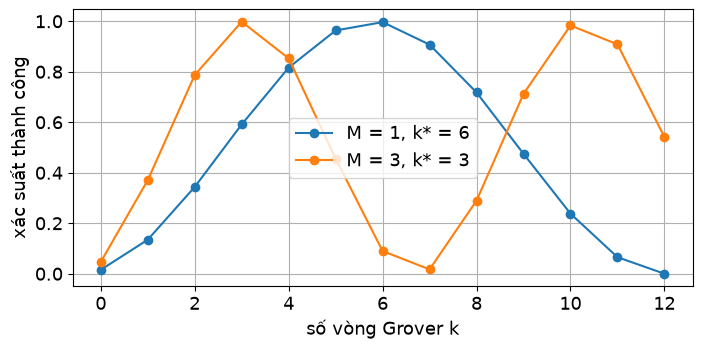

PASS


In [3]:
N = 64
fig, ax = plt.subplots()
ok = True
for M, c in [(1, "tab:blue"), (3, "tab:orange")]:
    theta = np.arcsin(np.sqrt(M / N))
    ks = np.arange(13)
    sv = np.array([grover_success_sv(N, M, k) for k in ks])
    err = np.max(np.abs(sv - np.sin((2 * ks + 1) * theta) ** 2))
    ok &= err < 1e-10
    kstar = int(np.round(np.pi / (4 * theta) - 0.5))
    ax.plot(ks, sv, "o-", color=c, label=f"M = {M}, k* = {kstar}")
    print(f"M = {M}: sai số so với công thức = {err:.1e}, k* = {kstar}, P(k*) = {sv[kstar]:.4f}")
ax.set_xlabel("số vòng Grover k"); ax.set_ylabel("xác suất thành công"); ax.legend(); plt.show()
print(verdict(ok))

## Cell 4 — Đo trên Aer tại k* (M = 1)
20 000 shot; tần suất phải nằm trong p ± 3σ.

In [4]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
N, M, n = 64, 1, 6
theta = np.arcsin(np.sqrt(M / N)); kstar = int(np.round(np.pi / (4 * theta) - 0.5))
s = np.ones(N) / np.sqrt(N)
oracle = np.diag([-1.0 if i < M else 1.0 for i in range(N)])
G = (2 * np.outer(s, s) - np.eye(N)) @ oracle
qc = QuantumCircuit(n, n)
qc.h(range(n))
qc.unitary(np.linalg.matrix_power(G, kstar), range(n), label=f"G^{kstar}")
qc.measure(range(n), range(n))
sim, shots = AerSimulator(seed_simulator=SEED), 20000
counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
freq = sum(v for b, v in counts.items() if int(b, 2) < M) / shots
p = np.sin((2 * kstar + 1) * theta) ** 2
sig = np.sqrt(p * (1 - p) / shots)
print(f"k* = {kstar}: p = {p:.4f}, tần suất = {freq:.4f}, 3σ = {3 * sig:.4f}", verdict(abs(freq - p) <= 3 * sig))

k* = 6: p = 0.9966, tần suất = 0.9967, 3σ = 0.0012 PASS
